Import and set up data

In [1]:
import seaborn as sns
import pandas as pd

import matplotlib.pyplot as plt

# load data
df = pd.read_csv("../Data/transformed_study_data.csv")

Heatmap

/var/folders/jj/x9p4qj9s3dz1rhh61kzc_v000000gn/T/ipykernel_49251/2826305579.py:15: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heatmap_data = df.pivot_table(


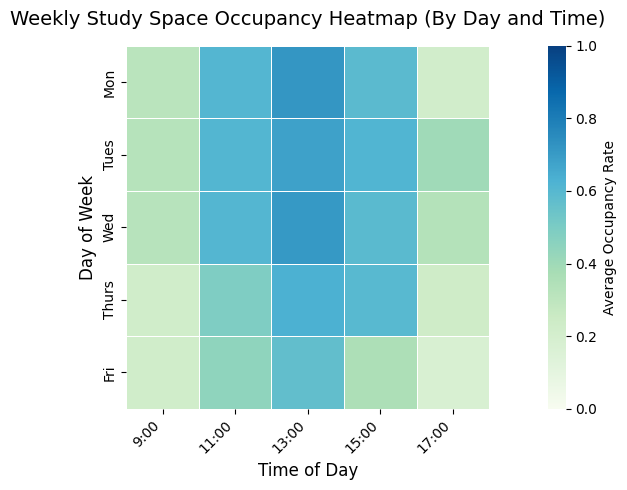

In [2]:
df['date'] = pd.to_datetime(df['date'])
full_to_custom = {
    'Sunday': 'Sun', 'Monday': 'Mon', 'Tuesday': 'Tues', 
    'Wednesday': 'Wed', 'Thursday': 'Thurs', 'Friday': 'Fri', 'Saturday': 'Sat'
}
df['day_of_week'] = df['date'].dt.day_name().map(full_to_custom)

# days of week order
day_order = ['Sun', 'Mon', 'Tues', 'Wed', 'Thurs', 'Fri', 'Sat']

# days of week becomes categorical type
df['day_of_week'] = pd.Categorical(df['day_of_week'], categories = day_order, ordered = True)

# pivot table: rows = days, cols = time slots, values = avg occ rate
heatmap_data = df.pivot_table(
    index = 'day_of_week',
    columns = 'time', 
    values ='occupancy_rate', 
    aggfunc ='mean'
)

# sort time
sorted_times = sorted(heatmap_data.columns, key=lambda x: pd.to_datetime(x, errors='coerce'))
heatmap_data = heatmap_data[sorted_times]

# plot heat map
plt.figure(figsize=(12, 5))
sns.heatmap(
    heatmap_data, 
    # (lighter = low occupancy, darker = high)
    cmap='GnBu',
    # add grid border
    linewidths=0.5,         
    cbar_kws={'label': 'Average Occupancy Rate'},
    # scale 0 to 100%
    vmin=0, vmax=1, 
    square = True         
)

# plotting
plt.title('Weekly Study Space Occupancy Heatmap (By Day and Time)', fontsize=14, pad=15)
plt.xlabel('Time of Day', fontsize=12)
plt.ylabel('Day of Week', fontsize=12)
plt.xticks(rotation = 45, ha = 'right')
plt.tight_layout()
plt.show()